# Quantum Support Vector Machine (QSVM) Demo with PennyLane and Qiskit

Quantum AI is an emerging field at the intersection of quantum computing and artificial intelligence that explores how quantum technologies can enhance the performance and capabilities of AI systems. By leveraging principles like superposition, entanglement, and quantum parallelism, quantum computing has the potential to dramatically accelerate computations in machine learning tasks, especially those involving complex optimization, high-dimensional data, or large-scale kernel methods. This could enable AI models to train faster, find better solutions, and handle problems that are currently intractable for classical computers.
This notebook demonstrates a simple Quantum Support Vector Machine (QSVM) using PennyLane.

We'll use:
- A synthetic 2D dataset (noisy circles)
- A 2-qubit quantum kernel
- Qiskit for circuit visualization
- PennyLane for training and evaluation

---

## 1. Introduction to Support Vector Machines (SVMs)


**Support Vector Machines (SVMs)** are powerful supervised learning models used for classification. The key idea is to find a decision boundary (a hyperplane) that **maximally separates** the classes.

**For linearly separable data**, the optimal hyperplane is the one with the **maximum margin** between the closest points from each class (called support vectors).

**When the data is not linearly separable**, we map it into a higher-dimensional space using a *kernel function*. This allows SVMs to find non-linear decision boundaries.

### Objective Function (Primal Form):
$$
\min_{w, b, \xi} \quad \frac{1}{2} ||w||^2 + C \sum_i \xi_i
\quad \text{such that} \quad y_i(w^T x_i + b) \geq 1 - \xi_i, \quad \xi_i \geq 0
$$
- $w$: weight vector
- $b$: bias term
- $C$: regularization parameter
- $\xi_i$: slack variables (allow for soft margin), quantifies how much the $i$-th data point violates the margin constraint. $\xi_i$ = 0 for correctly classified points outside the margin; $\xi_i$ > 0 for points inside the margin or misclassified.
---

## 2. Where Quantum Comes In

A **Quantum Kernel** uses quantum circuits to define a new way of comparing classical data.

### Quantum Feature Map
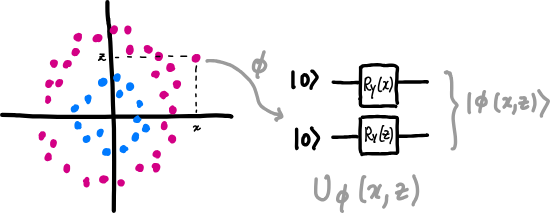

Fig. 1. Diagram of unitary circuit [1]

We encode classical data $x$ into a quantum state using a unitary circuit $U(x)$ and $\phi(x)$ represents the quantum feature map.

$$
|\phi(x)\rangle = U(x) |0\rangle
$$

### Quantum Kernel Function
$$
k(x, x') = |\langle \phi(x) | \phi(x') \rangle|^2
= |\langle 0 | U^\dagger(x) U(x') | 0 \rangle|^2
$$

This kernel measures **how similar two quantum states are**, via the overlap of their states.


### Why might this be powerful?
- Quantum states live in a **high-dimensional space**
- Even small circuits can encode **complex correlations**
- These quantum kernels might uncover structure that classical kernels cannot

The goal is to see if this extra structure gives us better classification performance.
---

---
## 3. Python Quantum Libraries

In [1]:
# Imports
# Install dependencies first:  pip install -r ../requirements.txt
import numpy as np
import matplotlib.pyplot as plt
import pennylane as qml
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from qiskit import QuantumCircuit

---
## 4. Demo dataset

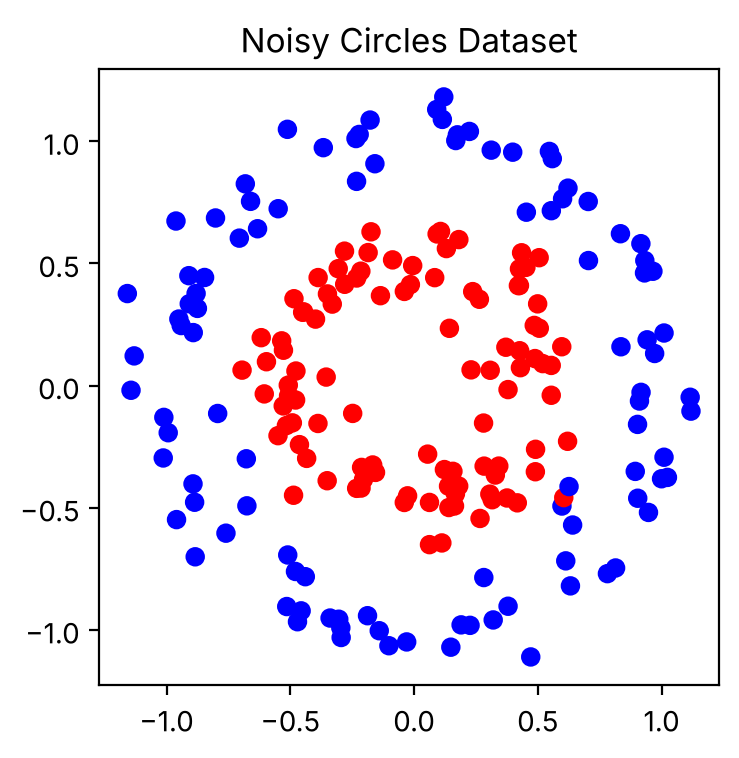

In [2]:
# Noisy circles dataset
X, y = make_circles(n_samples=200, noise=0.1, factor=0.5, random_state=42)
y = 2 * y - 1  # Convert labels to {-1, 1}
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

plt.figure(figsize=(4, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='bwr')
plt.title("Noisy Circles Dataset")
plt.show()

---
## 5. Designing a quantum feature map

In [3]:
# Simple 2-qubit feature map
n_qubits = 2
dev = qml.device('default.qubit', wires=n_qubits)

def feature_map(x):
    for i in range(n_qubits):
        qml.Hadamard(wires=i)
        qml.RZ(x[i] * np.pi, wires=i)
        qml.CNOT(wires=[i, (i+1)%n_qubits])

@qml.qnode(dev)
def kernel_circuit(x1, x2):
    feature_map(x1)
    qml.adjoint(feature_map)(x2)
    return qml.probs(wires=range(n_qubits))

def quantum_kernel(x1, x2):
    probs = kernel_circuit(x1, x2)
    return probs[0]  # overlap with |00>

---
## 6. Computing quantum kernel matrix

In [4]:
# Kernel matrix
def kernel_matrix(X1, X2):
    return np.array([[quantum_kernel(x1, x2) for x2 in X2] for x1 in X1])

K_train = kernel_matrix(X_train, X_train)
K_test = kernel_matrix(X_test, X_train)

---
## 7. QSVM training

Train Acc: 0.9929, Test Acc: 1.0000


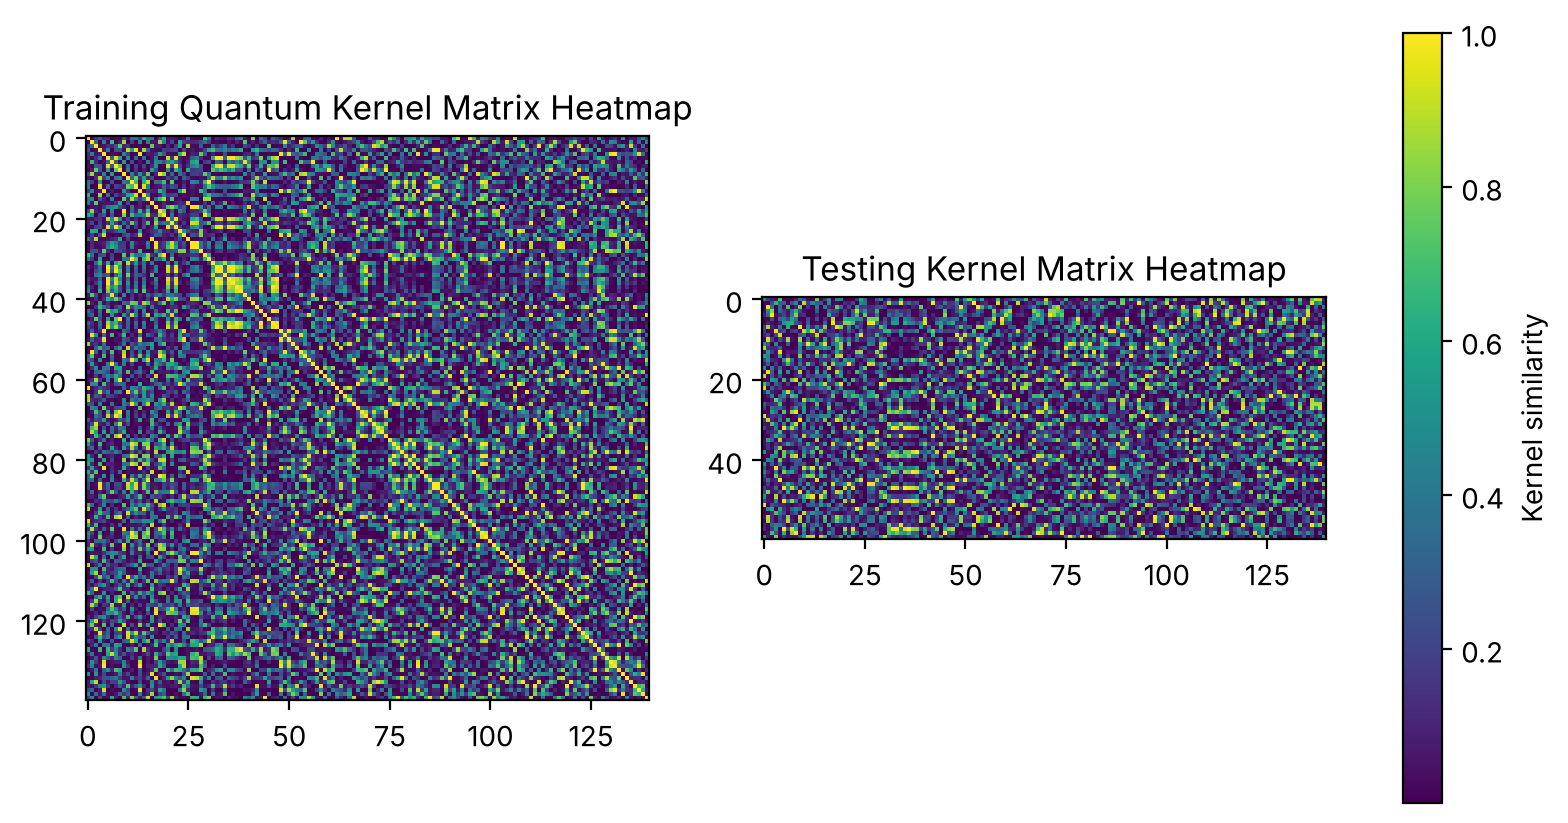

In [5]:
# Training SVM with precomputed quantum kernel
clf = SVC(kernel='precomputed')
clf.fit(K_train, y_train)

train_acc = clf.score(K_train, y_train)
test_acc = clf.score(K_test, y_test)
print(f"Train Acc: {train_acc:.4f}, Test Acc: {test_acc:.4f}")

# Visualising quantum kernel matrix heatmap
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
im = axs[0].imshow(K_train, interpolation='nearest', cmap='viridis')
axs[0].set_title('Training Quantum Kernel Matrix Heatmap')
axs[1].imshow(K_test, interpolation='nearest', cmap='viridis')
axs[1].set_title('Testing Kernel Matrix Heatmap')
fig.colorbar(im, ax=axs.ravel().tolist(), label='Kernel similarity')
plt.show()

---
## 8. Decision boundary

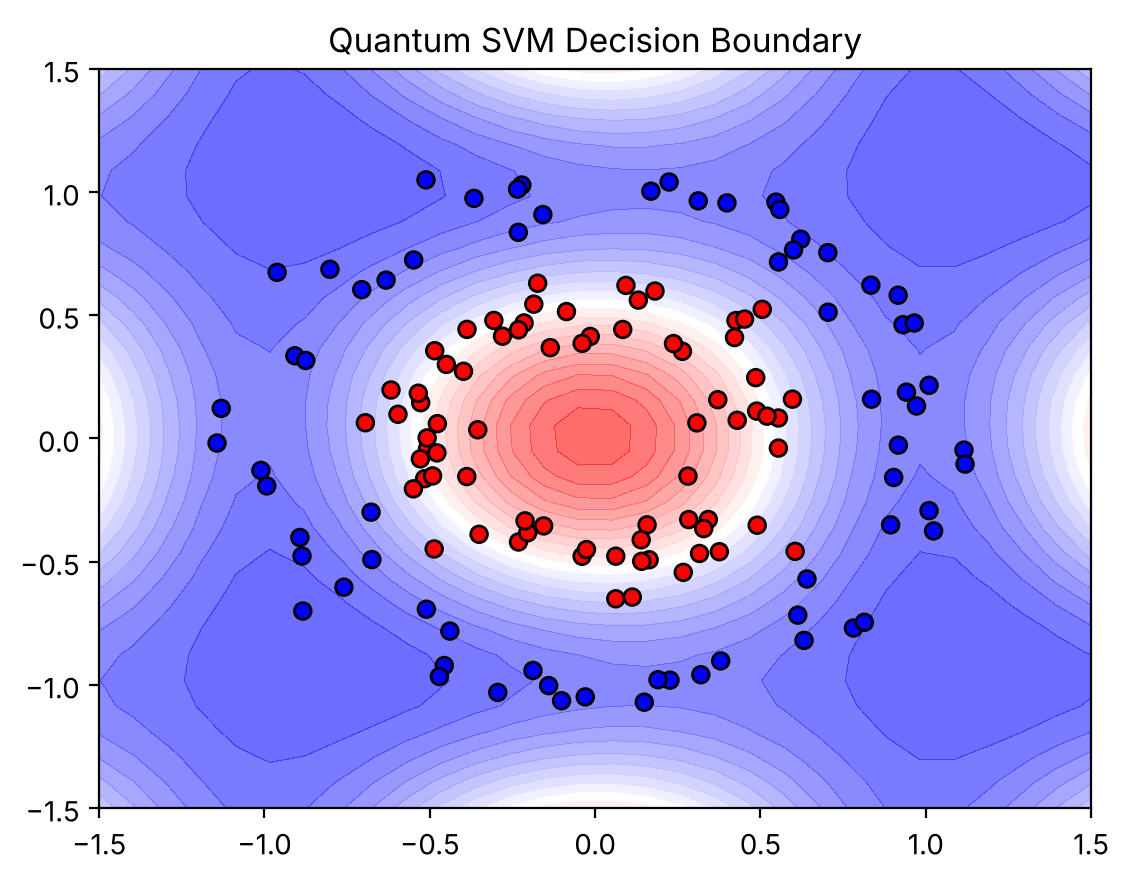

In [6]:
# Plotting decision boundary
import matplotlib
def plot_decision_boundary():
    xx, yy = np.meshgrid(np.linspace(-1.5, 1.5, 30), np.linspace(-1.5, 1.5, 30))
    grid = np.c_[xx.ravel(), yy.ravel()]
    K_grid = kernel_matrix(grid, X_train)
    Z = clf.decision_function(K_grid).reshape(xx.shape)

    plt.contourf(xx, yy, Z, levels=20, cmap="bwr", alpha=0.6)
    plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='bwr', edgecolor='k')
    plt.title("Quantum SVM Decision Boundary")
    plt.show()

plot_decision_boundary()

---
## 9. Visualising the feature map with Qiskit

The same feature map as above, drawn as a Qiskit circuit for a sample input $x = (0.4, 0.6)$.

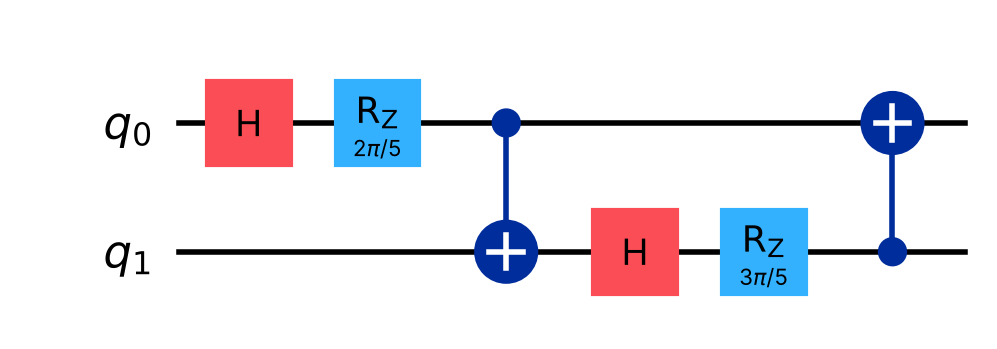

In [7]:
# Qiskit drawing of the feature map defined in section 5
def qiskit_feature_map(x):
    qc = QuantumCircuit(n_qubits)
    for i in range(n_qubits):
        qc.h(i)
        qc.rz(x[i] * np.pi, i)
        qc.cx(i, (i + 1) % n_qubits)
    return qc

qc = qiskit_feature_map([0.4, 0.6])
qc.draw('mpl')

---
## References

[1] PennyLane, “Quantum Feature Map,” PennyLane QML Glossary, 2025. [Online]. Available: https://pennylane.ai/qml/glossary/quantum_feature_map. [Accessed: Jul. 25, 2025].